# Powering the Planet

Energy production and consumption are among the main drivers of global economic development, but they also have significant environmental consequences.

This project explores the evolution of the global energy system and investigates the relationship between economic growth and CO₂ emissions. Using historical data from Our World in Data, the analysis examines changes in energy sources, regional differences and the environmental impact of economic activity.

The main objectives are:
- To analyze how the global energy mix has changed over time.
- To investigate the relationship between GDP and CO₂ emissions across countries and regions.
- To compare per capita emissions and identify differences in environmental impact.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

OVERVIEW

In [2]:
# download the dataset from the provided URL and print it to verify it has been downloaded correctly
try:
    url = "https://raw.githubusercontent.com/owid/energy-data/master/owid-energy-data.csv"
    df = pd.read_csv(url)
    print(f"This is a sample of the dataframe: {df.head()}")
except:
    raise Exception("Error loading the dataset. Please check the URL or your internet connection.")

This is a sample of the dataframe:          country  year iso_code  population  gdp  biofuel_cons_change_pct  \
0  ASEAN (Ember)  2000      NaN         NaN  NaN                      NaN   
1  ASEAN (Ember)  2001      NaN         NaN  NaN                      NaN   
2  ASEAN (Ember)  2002      NaN         NaN  NaN                      NaN   
3  ASEAN (Ember)  2003      NaN         NaN  NaN                      NaN   
4  ASEAN (Ember)  2004      NaN         NaN  NaN                      NaN   

   biofuel_cons_change_twh  biofuel_cons_per_capita  biofuel_consumption  \
0                      NaN                      NaN                  NaN   
1                      NaN                      NaN                  NaN   
2                      NaN                      NaN                  NaN   
3                      NaN                      NaN                  NaN   
4                      NaN                      NaN                  NaN   

   biofuel_elec_per_capita  ...  solar_share_

In [3]:
# print all the columns of the dataframe to have a more clear view of the variables
print(f"These are the {len(df.columns)} columns of the dataframe:")
for col in df.columns:
    print(col)

These are the 130 columns of the dataframe:
country
year
iso_code
population
gdp
biofuel_cons_change_pct
biofuel_cons_change_twh
biofuel_cons_per_capita
biofuel_consumption
biofuel_elec_per_capita
biofuel_electricity
biofuel_share_elec
biofuel_share_energy
carbon_intensity_elec
coal_cons_change_pct
coal_cons_change_twh
coal_cons_per_capita
coal_consumption
coal_elec_per_capita
coal_electricity
coal_prod_change_pct
coal_prod_change_twh
coal_prod_per_capita
coal_production
coal_share_elec
coal_share_energy
electricity_demand
electricity_demand_per_capita
electricity_generation
electricity_share_energy
energy_cons_change_pct
energy_cons_change_twh
energy_per_capita
energy_per_gdp
fossil_cons_change_pct
fossil_cons_change_twh
fossil_elec_per_capita
fossil_electricity
fossil_energy_per_capita
fossil_fuel_consumption
fossil_share_elec
fossil_share_energy
gas_cons_change_pct
gas_cons_change_twh
gas_consumption
gas_elec_per_capita
gas_electricity
gas_energy_per_capita
gas_prod_change_pct
gas_p

In [4]:
#show useful informations on the rows
year_min = df['year'].min()
year_max = df['year'].max()

print(f"The dataset covers the years from {year_min} to {year_max}.")
nations = df['country'].unique()

print(f"There are {len(nations)} different entities (considered nations, continents and groups).Here are the first 15 examples:")
print(nations[:15]) 

The dataset covers the years from 1900 to 2025.
There are 314 different entities (considered nations, continents and groups).Here are the first 15 examples:
<StringArray>
[      'ASEAN (Ember)',         'Afghanistan',              'Africa',
         'Africa (EI)',        'Africa (EIA)',      'Africa (Ember)',
      'Africa (Shift)',             'Albania',             'Algeria',
      'American Samoa',              'Angola',          'Antarctica',
 'Antigua and Barbuda',           'Argentina',             'Armenia']
Length: 15, dtype: str


MACRO-REGIONAL ANALYSIS OF ENERGY MIX AND RENEWABLE TRANSITION TRENDS

In [5]:
#searching for available macro-regions in the dataset
target_regions = ['World','Europe', 'North America', 'Asia', 'South America', 'Africa', 'Oceania']

valid_regions = []

for r in target_regions:
    if r in df['country'].unique():
        valid_regions.append(r) 
print("Found regions:", valid_regions)

#filtering the dataframe to include only valid regions
df_regions = df[df['country'].isin(valid_regions)]

# Selecting World data
df_world = df[df['country'] == 'World'].copy()

Found regions: ['World', 'Europe', 'North America', 'Asia', 'South America', 'Africa', 'Oceania']


In [6]:
#search for columns related to energy, electricity and CO2 emissions
#instead of using a a for cycle, I am using a list comprehension that has the same exact effectiveness since it is usully considered more elegant
energy_columns = [col for col in df.columns if 'electricity' in col.lower() or 'energy' in col.lower() or 'co2' in col.lower()]
print(f"energy columns are: {energy_columns}")

energy columns are: ['biofuel_electricity', 'biofuel_share_energy', 'coal_electricity', 'coal_share_energy', 'electricity_demand', 'electricity_demand_per_capita', 'electricity_generation', 'electricity_share_energy', 'energy_cons_change_pct', 'energy_cons_change_twh', 'energy_per_capita', 'energy_per_gdp', 'fossil_electricity', 'fossil_energy_per_capita', 'fossil_share_energy', 'gas_electricity', 'gas_energy_per_capita', 'gas_share_energy', 'hydro_electricity', 'hydro_energy_per_capita', 'hydro_share_energy', 'low_carbon_electricity', 'low_carbon_energy_per_capita', 'low_carbon_share_energy', 'nuclear_electricity', 'nuclear_energy_per_capita', 'nuclear_share_energy', 'oil_electricity', 'oil_energy_per_capita', 'oil_share_energy', 'other_renewable_electricity', 'other_renewable_exc_biofuel_electricity', 'other_renewables_energy_per_capita', 'other_renewables_share_energy', 'per_capita_electricity', 'primary_energy_consumption', 'renewables_electricity', 'renewables_energy_per_capita', 

Now we are ging to see how the global mix of energy sources changed from 1950 to 2022

In [7]:
# Selecting the main energy sources
mix_columns = [
    'coal_share_energy',
    'oil_share_energy',
    'gas_share_energy',
    'nuclear_share_energy',
    'renewables_share_energy'
]
# checking missing values and if the sum of the variables I chose as representative of the total are actually close to 100%
print(df_world[mix_columns].isna().sum())

# Calculate total energy share
df_world['total_share'] = df_world[mix_columns].sum(
    axis=1,
    min_count=len(mix_columns)
)


# Check total share
print(df_world[['year', 'total_share']])

coal_share_energy          66
oil_share_energy           66
gas_share_energy           66
nuclear_share_energy       66
renewables_share_energy    66
dtype: int64
       year  total_share
22864  1900          NaN
22865  1901          NaN
22866  1902          NaN
22867  1903          NaN
22868  1904          NaN
...     ...          ...
22985  2021      100.001
22986  2022      100.001
22987  2023      100.000
22988  2024      100.000
22989  2025          NaN

[126 rows x 2 columns]


In [8]:
# verify if the 66 missing values for every column, are in the same rows
missing_per_row = df_world[mix_columns].isna().sum(axis=1)

print(missing_per_row.value_counts().sort_index())

0    60
5    66
Name: count, dtype: int64


We can see how the missing values are in the same rows, so it basically means the dataframe has 66 years with missing values that would be excluded from the analysis. Also the variables choice looks like excellent,for the latest years it always sums up to 100%. I am going to verify it more precisely for every year since 4 observations are not enough.

In [9]:
# Removing observations with missing energy data
df_world_clean = df_world.dropna(subset=mix_columns)
print(df_world_clean[
    ~df_world_clean['total_share'].between(99.9, 100.1)
][['year', 'total_share']])

Empty DataFrame
Columns: [year, total_share]
Index: []


That means there are no rows with a total share out of the range 99,9 - 100,1 in the available years

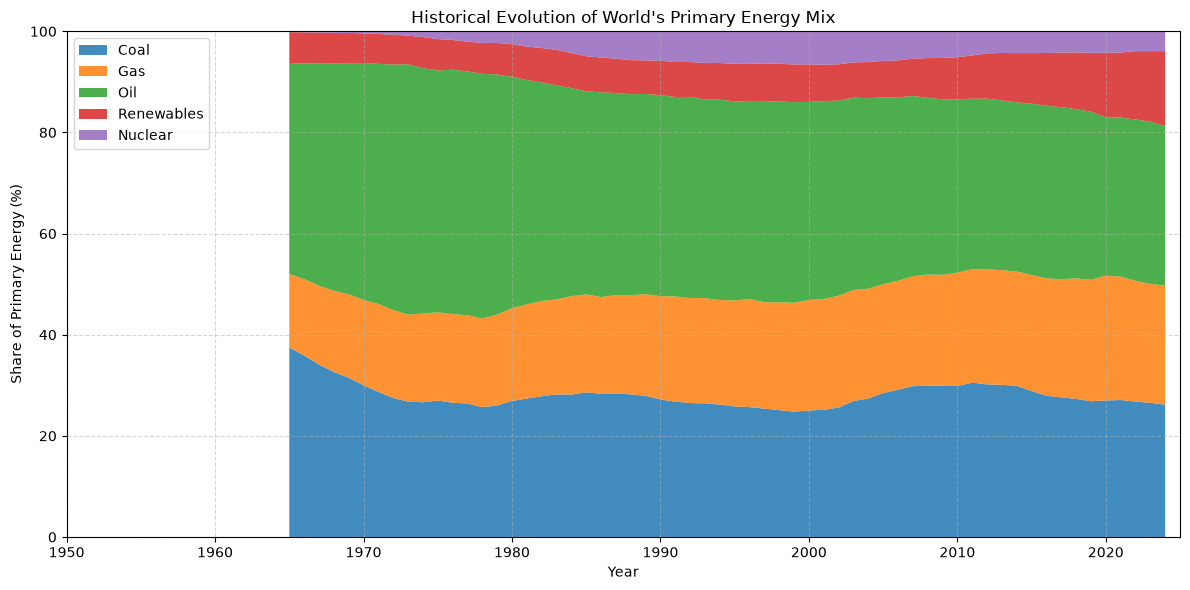

In [10]:
#filtering energy consuptions columns for the whole World, ignoring rows with missing data to represent the evolution in the energy source mix
mix_columns = [
    'coal_share_energy',
    'gas_share_energy',
    'oil_share_energy',
    'renewables_share_energy',
    'nuclear_share_energy'
]

# Keep only years with complete information, dropping rows with missing values
df_world_clean = df_world.dropna(subset=mix_columns).sort_values('year')

plt.figure(figsize=(12, 6))

plt.stackplot(
    df_world_clean['year'],
    *[df_world_clean[col] for col in mix_columns],
    labels=['Coal', 'Gas', 'Oil', 'Renewables', 'Nuclear'],
    alpha=0.85
)

plt.title("Historical Evolution of World's Primary Energy Mix")
plt.xlabel("Year")
plt.ylabel("Share of Primary Energy (%)")
plt.legend(loc='upper left')
plt.xlim(1950, 2025)
plt.ylim(0, 100)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [11]:
#since the graph starts from about 1965, I'm checking if there is a problem in my code verifying if a random coluumn has values before 1965
for vrb in mix_columns:
    first_nm_year= df_world[df_world[vrb].notnull()]['year'].min()
    last_nm_year= df_world[df_world[vrb].notnull()]['year'].max()
    print(f"The first available year for {vrb} is: {first_nm_year}")
    print(f"The last available year for {vrb} is: {last_nm_year}")

The first available year for coal_share_energy is: 1965
The last available year for coal_share_energy is: 2024
The first available year for gas_share_energy is: 1965
The last available year for gas_share_energy is: 2024
The first available year for oil_share_energy is: 1965
The last available year for oil_share_energy is: 2024
The first available year for renewables_share_energy is: 1965
The last available year for renewables_share_energy is: 2024
The first available year for nuclear_share_energy is: 1965
The last available year for nuclear_share_energy is: 2024


Now I can say that there are no available values before 1965 and after 2024 so our analysis from now on would focus on that range. I can also see that the graph gives a general idea of the evolution in the usage of the considered energy sources. On the other hand I think it is not very clear, so I am going to aggregate the fossil sources and renewable sources (considering the nuclear as a different subset).

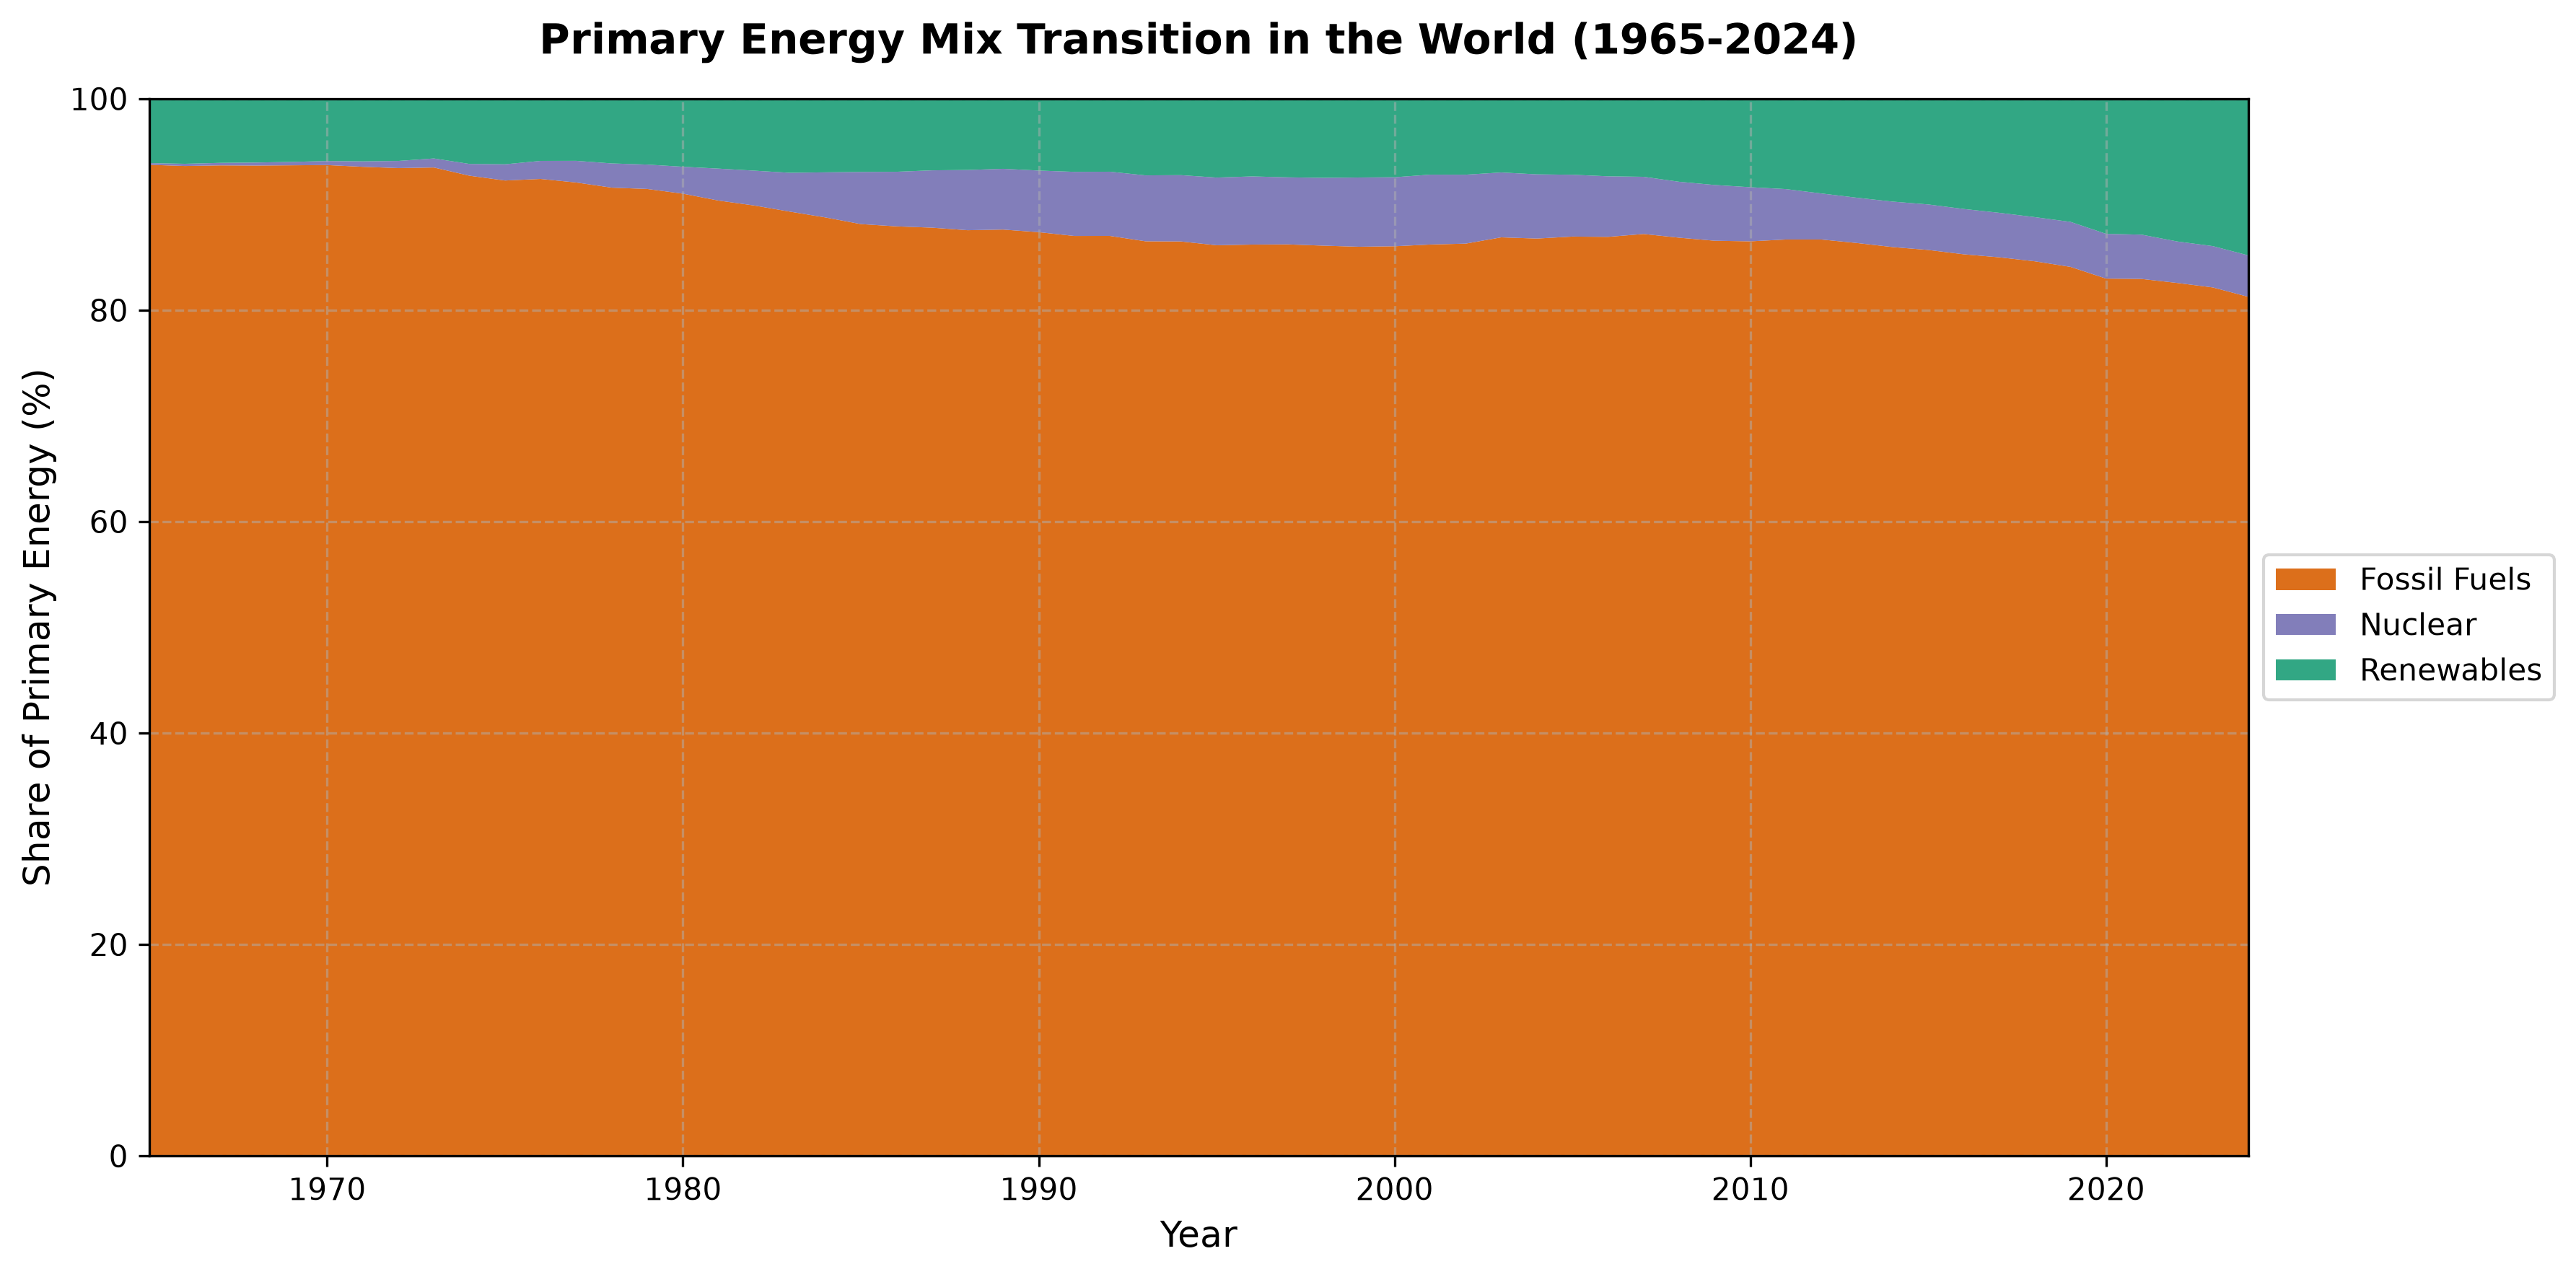

In [12]:
df_world = df_regions[df_regions['country'] == 'World'].copy()

df_world['total_fossil'] = (
    df_world['coal_share_energy'] +
    df_world['gas_share_energy'] +
    df_world['oil_share_energy']
)

# Keep only the period 1965-2024
df_world = df_world[df_world['year'].between(1965, 2024)]

# Aggregate energy sources by year
df_plot = (
    df_world.groupby('year')[
        ['total_fossil', 'nuclear_share_energy', 'renewables_share_energy']
    ].mean().reset_index()
)

df_plot = df_plot.sort_values('year')

plt.figure(figsize=(12, 6), dpi=300)

plt.stackplot(
    df_plot['year'],
    df_plot['total_fossil'],
    df_plot['nuclear_share_energy'],
    df_plot['renewables_share_energy'],
    labels=['Fossil Fuels', 'Nuclear', 'Renewables'],
    colors=['#d95f02', '#7570b3', '#1b9e77'],
    alpha=0.9
)

# Graphic improvements
plt.title('Primary Energy Mix Transition in the World (1965-2024)',
          fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Share of Primary Energy (%)', fontsize=12)

plt.xlim(1965, 2024)
plt.ylim(0, 100)

plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), frameon=True)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

plt.show()


Now we can clearly see how renewables have been constantly growing, especially in the last decade due to various reasons, such as laws, climate policies and cost reductions. nuclear energy consumption instead experienced its "boom" in the early 1980s but later stabilized and even reduced because of the Chernobyl disaster in 1986 alongside other challenges such as high building costs and radioactive waste management.

Moving forward, this analysis will primarily focus on Europe, North America and Asia. This selection is justified by their combined share of global primary energy consumption, which currently stands at approximately 91.5%.

Furthermore, Europe and North America have historically been the main drivers of industrialization and are now subject to strict environmental regulations. On the other hand, Asia has emerged as a major global player, accounting for the largest share of global energy demand while also leading worldwide investments in renewable energy infrastructure.

I will also examine the other continents to identify any distinctive trends or developments. For example, South America is expected to show a significant share of hydropower in its energy mix. However, given their relatively small contribution to global energy consumption, these regions will play a secondary role in the overall analysis.



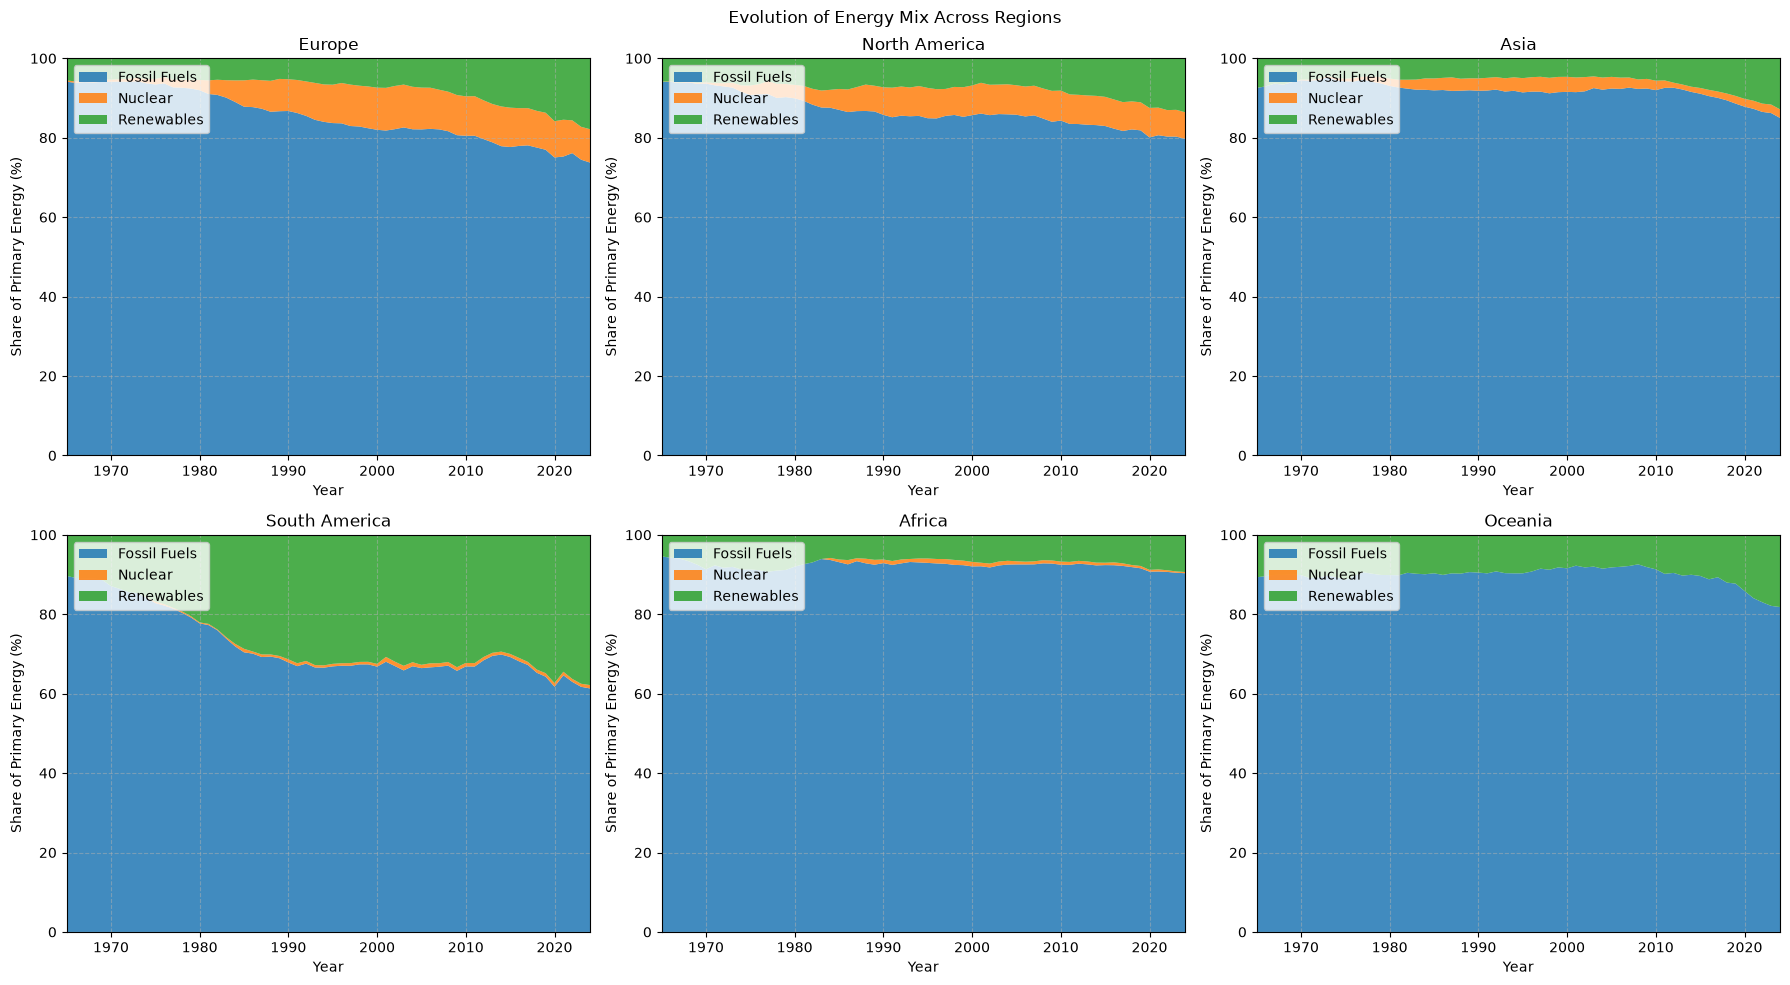

In [13]:
target_comparison = [
    'Europe', 'North America', 'Asia',
    'South America', 'Africa', 'Oceania'
]

# Create six subplots
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for ax, region in zip(axes, target_comparison):

    df_temp = df_regions[
        df_regions['country'] == region
    ].copy()

    # Keep only complete observations
    df_temp = df_temp.dropna(subset=mix_columns)

    df_temp['total_fossil'] = (
        df_temp['coal_share_energy'] +
        df_temp['gas_share_energy'] +
        df_temp['oil_share_energy']
    )

    df_temp = df_temp.sort_values('year')

    ax.stackplot(
        df_temp['year'],
        df_temp['total_fossil'],
        df_temp['nuclear_share_energy'],
        df_temp['renewables_share_energy'],
        labels=['Fossil Fuels', 'Nuclear', 'Renewables'],
        alpha=0.85
    )

    ax.set_title(region)
    ax.set_xlabel('Year')
    ax.set_ylabel('Share of Primary Energy (%)')
    ax.set_ylim(0, 100)

    # Remove empty space before the first year and after the last year
    ax.set_xlim(1965, 2024)
    ax.margins(x=0)

    ax.legend(loc='upper left')
    ax.grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Evolution of Energy Mix Across Regions')
plt.tight_layout()
plt.show()



As illustrated from the data, from the early 1970s in Europe and North America and from the 1980s in Asia, the share of nuclear energy had been growing very fast until the mid 1980s. Following this period their growing rate decreased until the beginning of the new century where it stabilized and even got negative. The renewables instead, in all the 3 continents, mantained the same share for a very long period: from 1965 to about 2005 for Europe and North America and 2012 for Asia. After this period the renewables share experienced a constatly growing rate trough the end of the considered period (2025). 

As expected, South America presents a distinctive pattern: it has the largest renewables share among all the other continent, with a particularly rapid growth rate from 1970 to 1990. On the other hand Africa shows relatively stable shares in all the sources, while Oceania follows the trend of the Western continents. It is also worth noticing that Oceania presents a null share on nuclear energy.

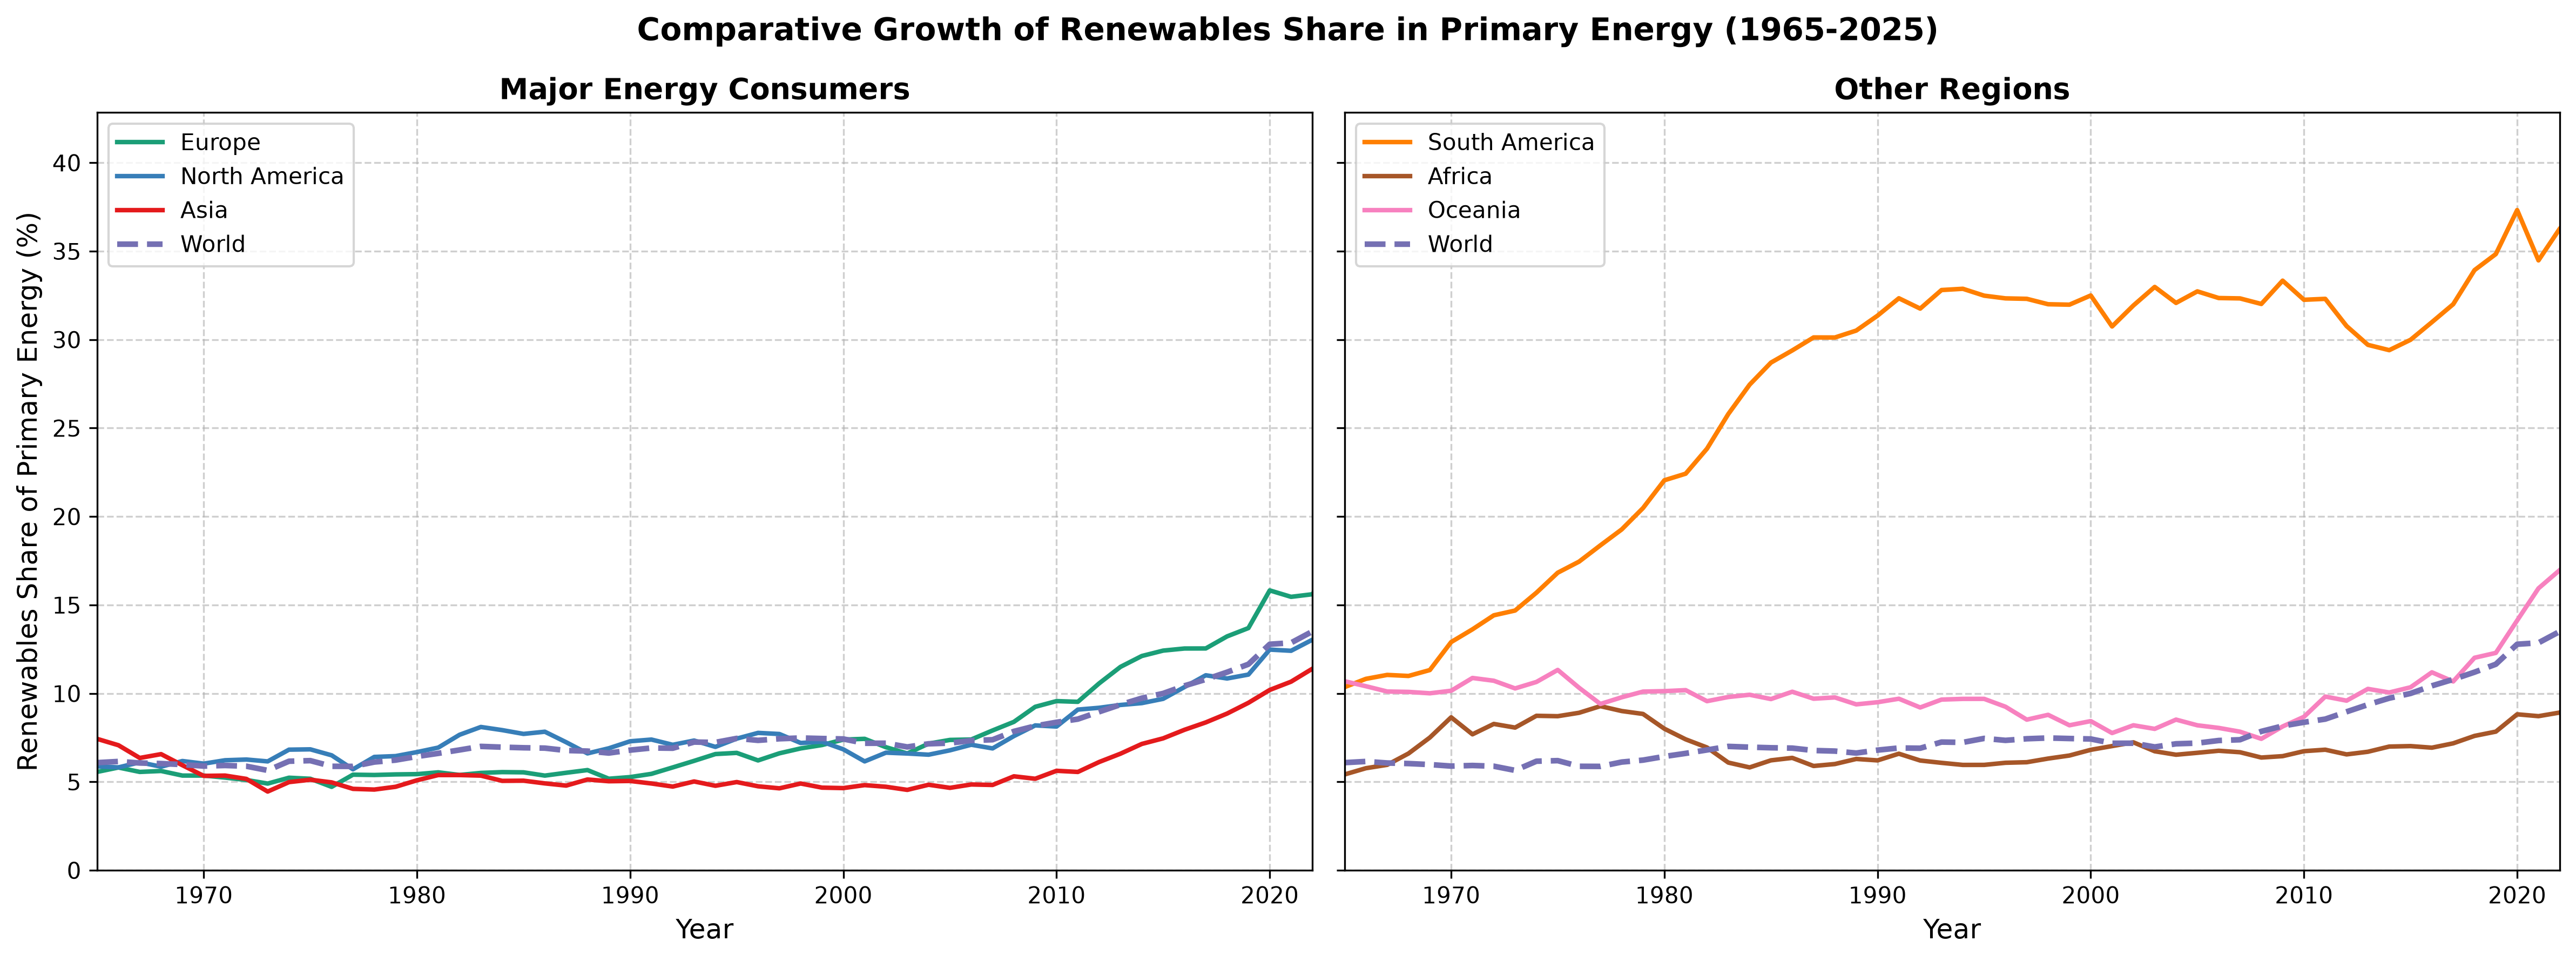

In [14]:
# First graph: Major energy consumers
target_regions_1 = ['Europe', 'North America', 'Asia', 'World']

# Second graph: Other regions
target_regions_2 = ['South America', 'Africa', 'Oceania', 'World']

region_colors = {
    'Europe': '#1b9e77',
    'North America': '#377eb8',
    'Asia': '#e41a1c',
    'South America': '#ff7f00',
    'Africa': '#a65628',
    'Oceania': '#f781bf',
    'World': '#7570b3'
}

fig, axes = plt.subplots(1, 2, figsize=(16, 6), dpi=300, sharey=True)

for ax, target_regions in zip(axes, [target_regions_1, target_regions_2]):

    for region in target_regions:
        df_temp = df_regions[
            df_regions['country'] == region
        ].sort_values('year')

        ax.plot(
            df_temp['year'],
            df_temp['renewables_share_energy'],
            label=region,
            color=region_colors[region],
            linestyle='--' if region == 'World' else '-',
            linewidth=2.5 if region == 'World' else 2
        )

    ax.set_xlabel("Year", fontsize=12)
    ax.set_xlim(1965-2024)
    ax.set_ylim(0, df_regions['renewables_share_energy'].max() + 5)
    ax.set_xlim(1965, 2022)
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend(loc='upper left', fontsize=10)

axes[0].set_title("Major Energy Consumers", fontsize=13, fontweight='bold')
axes[1].set_title("Other Regions", fontsize=13, fontweight='bold')

axes[0].set_ylabel("Renewables Share of Primary Energy (%)", fontsize=12)

fig.suptitle(
    "Comparative Growth of Renewables Share in Primary Energy (1965-2025)",
    fontsize=14,
    fontweight='bold'
)

plt.tight_layout()
plt.show()


The data show that North America (at least from the 1990s) has more or less followed the world trend in terms of renewable energy share. Europe has been below the World average until around 2000 when it inverted the trend, meanwhile Asia has always been way below from the late 1960s.

For the other regions, as already suggested by the previous graph, South America is the total leader in the renewables' share of primary energy consuption, while Oceania developed mostly from the late 2000s and Africa has only regitered a slight improvement in the latest period.







HOW CO₂ EMISSIONS RELATE TO GDP AND POPULATION

In [15]:
# Searching for CO₂-related variables in the Energy dataset
co2_columns = [
    col for col in df.columns
    if 'co2' in col.lower() or 'carbon' in col.lower()
]

print("CO2-related variables found:", co2_columns)

# Searching for greenhouse gas-related variables
greenhouse_columns = [
    col for col in df.columns
    if 'greenhouse' in col.lower()
]

print("Greenhouse gas variables found:", greenhouse_columns)

CO2-related variables found: ['carbon_intensity_elec', 'low_carbon_cons_change_pct', 'low_carbon_cons_change_twh', 'low_carbon_consumption', 'low_carbon_elec_per_capita', 'low_carbon_electricity', 'low_carbon_energy_per_capita', 'low_carbon_share_elec', 'low_carbon_share_energy']
Greenhouse gas variables found: ['greenhouse_gas_emissions']


The Energy dataset contains several carbon related indicators, such as carbon intensity and low-carbon energy consumption. However, these variables do not directly measure total CO₂ emissions. In addiction I also found some greenhouse gasses related indicators but nothing specifically referred to CO₂. Therefore, to investigate the relationship between economic growth and CO₂ emissions, I decided to use the dedicated Our World in Data CO₂ dataset.

In [16]:
# Loading CO₂ dataset
url1='https://raw.githubusercontent.com/owid/co2-data/master/owid-co2-data.csv'
try:
    df_co2 = pd.read_csv('https://raw.githubusercontent.com/owid/co2-data/master/owid-co2-data.csv'
)
except:
    raise Exception("Error loading the dataset. Please check the URL or your internet connection.")

print(df_co2.shape)
print(df_co2.columns.tolist())
print(df_co2.head())

(56269, 79)
['country', 'year', 'iso_code', 'population', 'gdp', 'cement_co2', 'cement_co2_per_capita', 'co2', 'co2_growth_abs', 'co2_growth_prct', 'co2_including_luc', 'co2_including_luc_growth_abs', 'co2_including_luc_growth_prct', 'co2_including_luc_per_capita', 'co2_including_luc_per_gdp', 'co2_including_luc_per_unit_energy', 'co2_per_capita', 'co2_per_gdp', 'co2_per_unit_energy', 'coal_co2', 'coal_co2_per_capita', 'consumption_co2', 'consumption_co2_per_capita', 'consumption_co2_per_gdp', 'cumulative_cement_co2', 'cumulative_co2', 'cumulative_co2_including_luc', 'cumulative_coal_co2', 'cumulative_flaring_co2', 'cumulative_gas_co2', 'cumulative_luc_co2', 'cumulative_oil_co2', 'cumulative_other_co2', 'energy_per_capita', 'energy_per_gdp', 'flaring_co2', 'flaring_co2_per_capita', 'gas_co2', 'gas_co2_per_capita', 'ghg_excluding_lucf_per_capita', 'ghg_per_capita', 'land_use_change_co2', 'land_use_change_co2_per_capita', 'methane', 'methane_per_capita', 'nitrous_oxide', 'nitrous_oxide_p

In [17]:
# Check missing values in the main variables
print(df_co2[['co2', 'gdp', 'population']].isna().sum())

# Check the time range
print("First year:", df_co2['year'].min())
print("Last year:", df_co2['year'].max())

# Check data availability by decade

df_co2['decade'] = (df_co2['year'] // 10) * 10

print(
    df_co2.groupby('decade')[['co2', 'gdp', 'population']]
    .count()
)


co2           26050
gdp           40902
population    12145
dtype: int64
First year: 1750
Last year: 2025
         co2   gdp  population
decade                        
1750     160     0          96
1760     160     0          96
1770     160     0          96
1780     175     0          96
1790     206     0          97
1800     234     0         942
1810     241     0         948
1820     250   122         957
1830     346   121        1045
1840     311   135         991
1850     528   181        2093
1860     737   180        2096
1870     847   291        2096
1880     871   262        2096
1890     974   289        2096
1900    1016   379        2101
1910    1072   429        2099
1920    1168   501        2101
1930    1294   525        2100
1940    1335   480        2098
1950    2137  1459        2340
1960    2267  1471        2340
1970    2340  1495        2340
1980    2346  1626        2340
1990    2492  1639        2340
2000    2520  1641        2340
2010    2520  1646        

In [18]:
# Since the 1950s look like the first decade with a sufficient amount of data, I will focus my analysis from 1950 onwards. 2022 is the last year with a sufficient amount of data, so for the same reason it would be the last year considered
recent_data = df_co2[df_co2['year'] >= 1950]

print(recent_data[['co2', 'gdp', 'population']].isna().sum())

# Check duplicate country-year observations
print("Duplicates:", df_co2.duplicated(
    subset=['country', 'year']
).sum())
# Number of available observations since 1950
print("CO2:", recent_data['co2'].notna().sum())
print("GDP:", recent_data['gdp'].notna().sum())
print("Population:", recent_data['population'].notna().sum())

# Observations with all three variables available
complete_data = recent_data.dropna(
    subset=['co2', 'gdp', 'population']
)

print("Complete observations:", len(complete_data))

co2           1480
gdp           8142
population    1830
dtype: int64
Duplicates: 0
CO2: 18134
GDP: 11472
Population: 17784
Complete observations: 11252


In [19]:
# selecting the most representative columns
columns_of_interest = [
    'country',
    'year',
    'co2',
    'gdp',
    'population'
]

df_co2_analysis = df_co2[columns_of_interest]

df_co2_analysis = df_co2_analysis[
    df_co2_analysis['year'] >= 1950
]
# dropping rows with null values on the core variables
df_co2_analysis = df_co2_analysis.dropna(
    subset=['co2', 'gdp', 'population']
)

In [20]:
# controlling the previous code worked as wanted: expecting zero null values and 5 columns and time range from 1950 to 2022. Checking also how many countries are in the dataframe



print(df_co2_analysis.shape)

print(df_co2_analysis.isna().sum())

print("First year:", df_co2_analysis['year'].min())
print("Last year:", df_co2_analysis['year'].max())

print("Number of entities:",
      df_co2_analysis['country'].nunique())


(11252, 5)
country       0
year          0
co2           0
gdp           0
population    0
dtype: int64
First year: 1950
Last year: 2022
Number of entities: 165


In [21]:
# checking if 1950 is a suitable starting point for comparing
print(df_co2_analysis.groupby('year').size())

year
1950    128
1951    129
1952    135
1953    135
1954    135
       ... 
2018    165
2019    165
2020    165
2021    165
2022    165
Length: 73, dtype: int64


In [22]:
# Selecting global CO₂ emissions
df_world_co2 = df_co2_analysis[
    df_co2_analysis['country'] == 'World'
]

df_world_co2 = df_world_co2.sort_values('year')

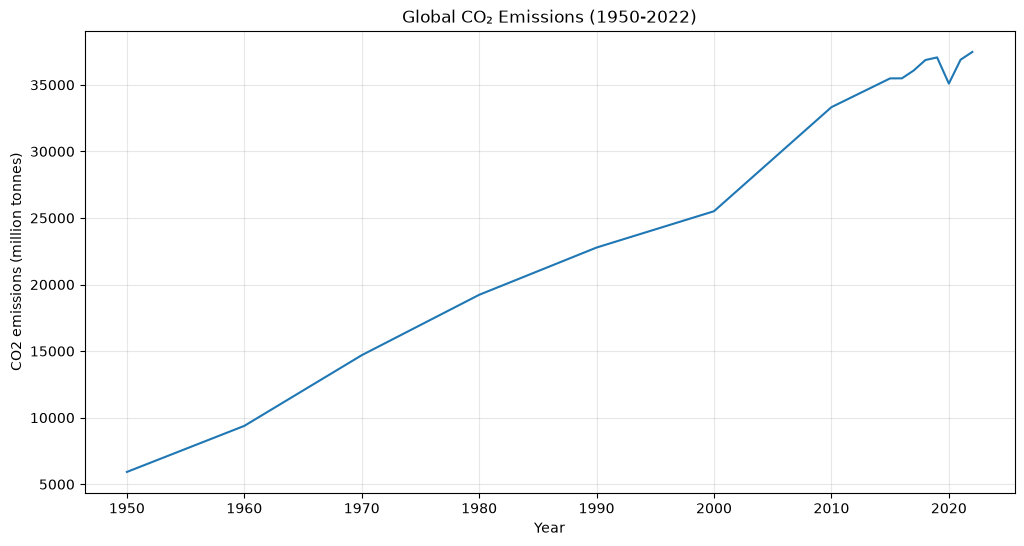

In [23]:
plt.figure(figsize=(12, 6))

plt.plot(
    df_world_co2['year'],
    df_world_co2['co2']
)

plt.title('Global CO₂ Emissions (1950-2022)')
plt.xlabel('Year')
plt.ylabel('CO2 emissions (million tonnes)')
plt.grid(True, alpha=0.3)

plt.show()

Global CO₂ emissions generally increased between 1950 and 2022. Although the overall trend is clearly upward, the rate of growth varied across the decades. The most noticeable decline occurred in 2020, coinciding with the COVID-19 pandemic, after which emissions quickly rebounded. Another turning point is the beginning of the 2000s, when the slope of the line became steeper.

In [24]:
# check if this dataset contains the aggregate values per continent
regions = [
    'Europe', 'North America', 'South America',
    'Asia', 'Africa', 'Oceania', 'World'
]

df_co2_regions = df_co2[
    df_co2['country'].isin(regions)
][['country', 'year', 'co2', 'population']]

df_co2_regions = df_co2_regions[
    df_co2_regions['year'].between(1950, 2022)
]

# Summary of data availability
 # # Summary of data availability

# The first lambda function creates a new 'missing_co2' column: it takes the 'co2' values, identifies missing values (True = 1, False = 0),calculates their mean, converts it into a percentage and rounds it to the first decimal place.

df_co2_regions.groupby('country').agg(
    years_available=('year', 'count'),
    missing_co2=('co2', lambda x: round(x.isna().mean() * 100, 1))
)
df_co2_regions.groupby('country').agg(
    years_available=('year', 'count'),
    missing_co2=('co2', lambda x: round(x.isna().mean() * 100, 1)),
    missing_population=('population', lambda x: round(x.isna().mean() * 100, 1))
)

 

,years_available,missing_co2,missing_population
country,,,
Africa,73,0.0,0.0
Asia,73,0.0,0.0
Europe,73,0.0,0.0
North America,73,0.0,0.0
Oceania,73,0.0,0.0
South America,73,0.0,0.0
World,73,0.0,0.0


This is the best possible result for our analysis: there are available data for the aggregate continents with no missing data on "co2" and "population"

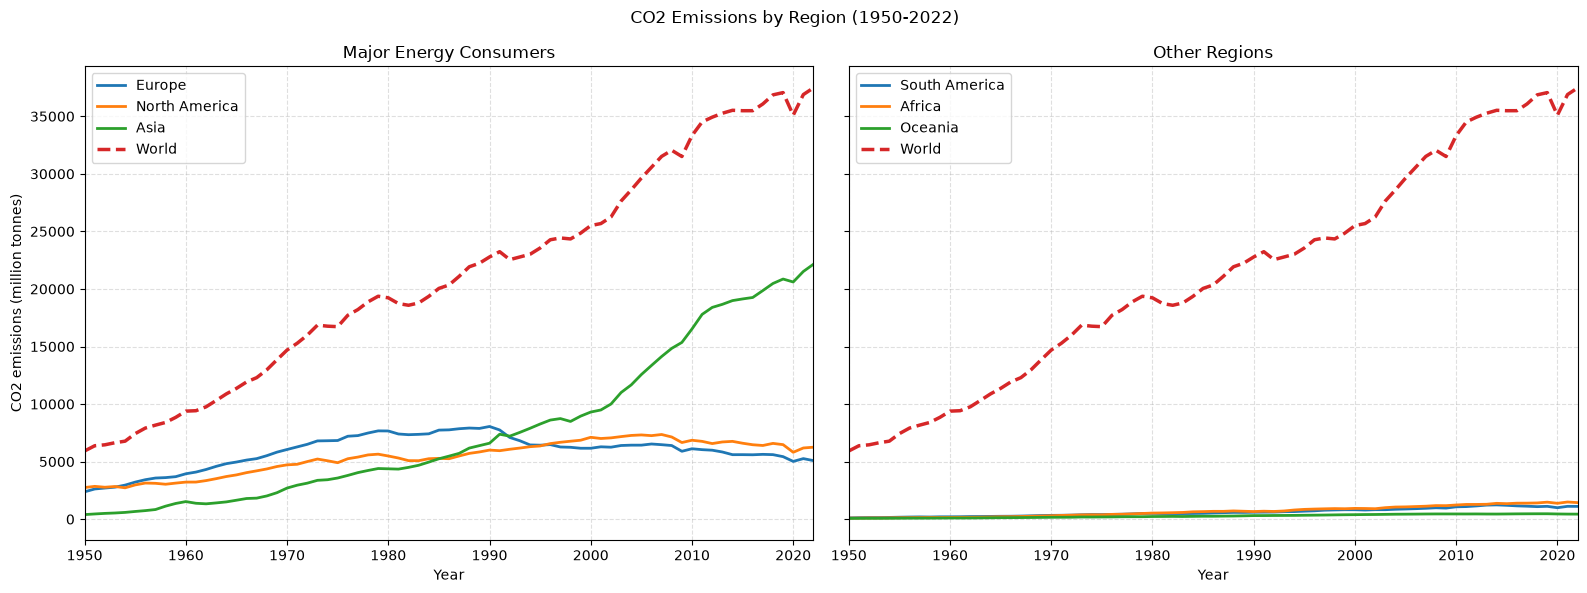

In [25]:
target_regions_1 = ['Europe', 'North America', 'Asia', 'World']
target_regions_2 = ['South America', 'Africa', 'Oceania', 'World']

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

for ax, target_regions in zip(axes, [target_regions_1, target_regions_2]):

    for region in target_regions:
        df_temp = df_co2_regions[
            df_co2_regions['country'] == region
        ].sort_values('year')

        ax.plot(
            df_temp['year'],
            df_temp['co2'],
            label=region,
            linewidth=2.5 if region == 'World' else 2,
            linestyle='--' if region == 'World' else '-'
        )

    ax.set_xlabel('Year')
    ax.set_xlim(1950, 2022)
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend()

axes[0].set_title('Major Energy Consumers')
axes[1].set_title('Other Regions')
axes[0].set_ylabel('CO2 emissions (million tonnes)')

fig.suptitle('CO2 Emissions by Region (1950-2022)')
plt.tight_layout()
plt.show()

In the graph on the left, we can see how Europe and North America decreased or at least stabilized their emissions from the early 1990s, after growing in the previous period. Asia, on the other hand has been growing non-stop and even got a steeper emissions line fom the 2000s.

In the graph on the right, emissions from all the other regions have also increased over time. However, due to the shared vertical scale, their emission levels appear relatively close to zero when compared with those of the major emitting regions.

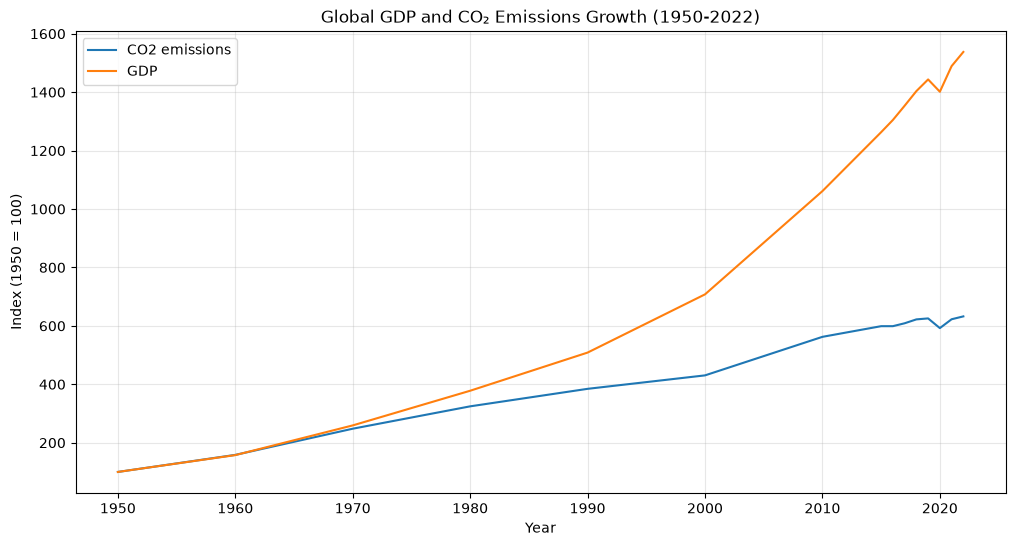

In [26]:
# Comparing global GDP and CO₂ emissions growth using indexes to compare their growth rates despite different scales

df_world_co2 = df_world_co2.sort_values('year')

df_world_co2['co2_index'] = (
    df_world_co2['co2'] / df_world_co2['co2'].iloc[0] * 100
)

df_world_co2['gdp_index'] = (
    df_world_co2['gdp'] / df_world_co2['gdp'].iloc[0] * 100
)

plt.figure(figsize=(12, 6))

plt.plot(df_world_co2['year'], df_world_co2['co2_index'],
         label='CO2 emissions')

plt.plot(df_world_co2['year'], df_world_co2['gdp_index'],
         label='GDP')

plt.title('Global GDP and CO₂ Emissions Growth (1950-2022)')
plt.xlabel('Year')
plt.ylabel('Index (1950 = 100)')
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

GDP and CO₂ emissions follow a similar trend: both increase steadily until 2000, when their growth rate become snoticeably steeper.Both also experience a temporary decline in the COVID-19 period, followed by a quick rebound. Overall the GDP has a higher growth rate than CO₂ emissions suggesting a relative decoupling: the emissions have been growing but at a significantly slower rate than gdp

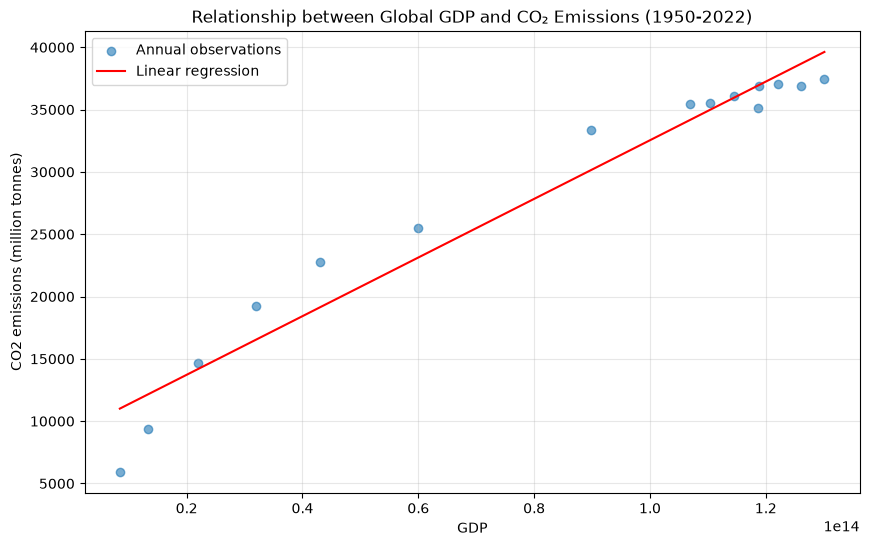

Correlation coefficient: 0.975
R-squared: 0.951


In [27]:
# Selecting GDP and CO2 values
x = df_world_co2['gdp']
y = df_world_co2['co2']

# Calculating linear regression
slope, intercept = np.polyfit(x, y, 1)

# Creating regression line
x_line = np.linspace(x.min(), x.max(), 100)
y_line = slope * x_line + intercept

# Calculating correlation coefficient and R-squared
correlation = np.corrcoef(x, y)[0, 1]
r_squared = correlation**2

# Plotting
plt.figure(figsize=(10, 6))

plt.scatter(x, y, alpha=0.6, label='Annual observations')
plt.plot(x_line, y_line, color='red', label='Linear regression')

plt.title('Relationship between Global GDP and CO₂ Emissions (1950-2022)')
plt.xlabel('GDP')
plt.ylabel('CO2 emissions (million tonnes)')
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

print("Correlation coefficient:", round(correlation, 3))
print("R-squared:", round(r_squared, 3))

Overall, there appears to be a positive correlation between GDP and CO₂ emissions, confirmed by the correlation cofficient of 0,975.Furthermore, the R-squared value of 0.951 indicates that the linear regression model explains approximately 95.1% of the variation in CO₂ emissions. 

On the other hand, this strong correlation does not necessarily imply causation, as both variables have followed an upward trend over time. However, at higher GDP levels (corresponding to more recent years), CO₂ emissions appear to have grown at a significantly slower rate than GDP, suggesting a possible relative decoupling between economic growth and environmental impact. Nevertheless, this observation should be interpreted cautiously, as the high correlation coefficient may partly reflect the common upward trends of the two variables (growing up) rather than a direct economic relationship.

In [36]:
import pycountry_convert as pc
# get an ISO code and return the corresponding continent
def get_continent(iso):
    try:
        country_alpha2 = pc.country_alpha3_to_country_alpha2(iso)
        continent_code = pc.country_alpha2_to_continent_code(country_alpha2)
        return pc.convert_continent_code_to_continent_name(continent_code)
    except:
        return None

In [29]:
# select the relevant data
df_gdp_co2_countries = df_co2[
    (df_co2['year'].between(1950, 2022)) &
    (df_co2['iso_code'].notna())
][['country', 'iso_code', 'year', 'gdp', 'co2', 'population']]

# create a new column by applying the 'get_continent(iso)' function to all the ISO codes
df_gdp_co2_countries['continent'] = (
    df_gdp_co2_countries['iso_code'].apply(get_continent)
)

In [30]:
# create a new dataframe exluding Antarctica and the non-assigned countries
df_analysis = df_gdp_co2_countries[
    (df_gdp_co2_countries['continent'] != 'Antarctica') &
    (df_gdp_co2_countries['continent'].notna())
]

In [31]:
# summing the 'gdp','co2','population' values withimn each continent and year. (min_count=1) tells Pandas to return "NaN" when there are no available values
df_continents = (
    df_analysis
    .groupby(['continent', 'year'], as_index=False).agg(
        gdp=('gdp', lambda x: x.sum(min_count=1)),
        co2=('co2', lambda x: x.sum(min_count=1)),
        population=('population', lambda x: x.sum(min_count=1))
    )
)

In [32]:
# multiplying 'co2' by 1,000,000 because the value is expressed in millions of tonnes
df_continents['co2_per_capita'] = (
    df_continents['co2'] * 1_000_000 /
    df_continents['population']
)

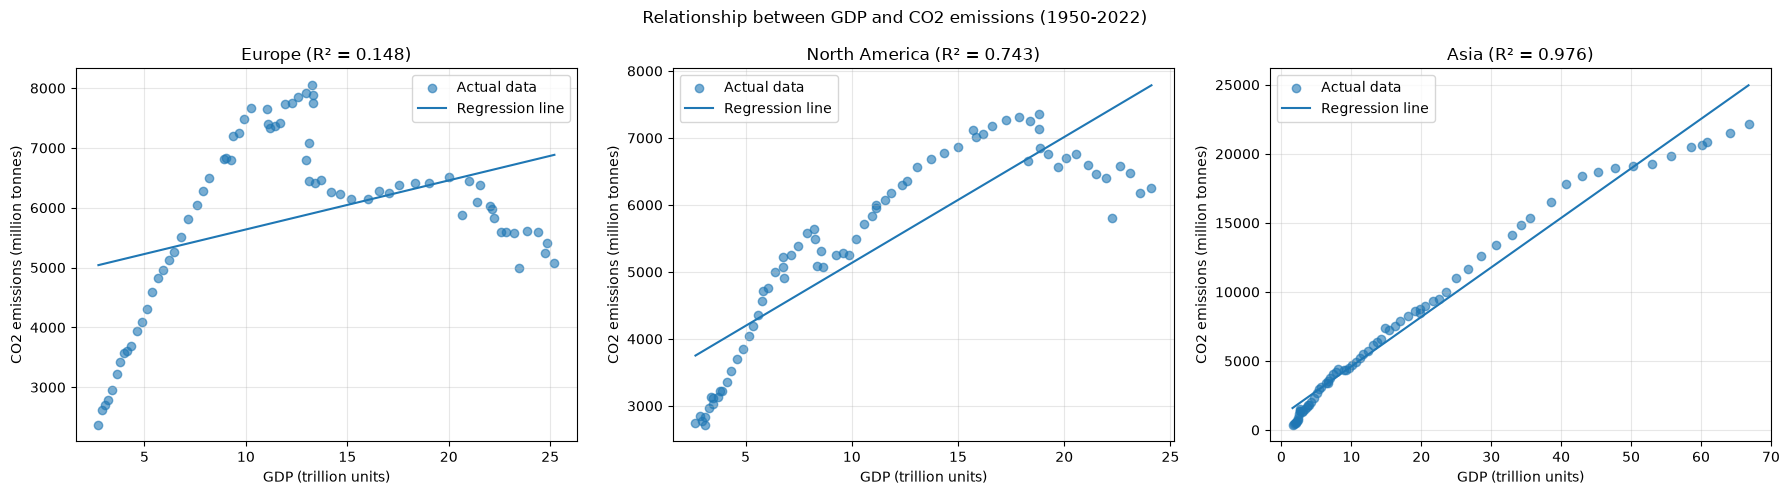

In [33]:
target_continents = ['Europe', 'North America', 'Asia']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, continent in zip(axes, target_continents):

    data = df_continents[
        df_continents['continent'] == continent
    ].dropna(subset=['gdp', 'co2'])

    x = data['gdp'] / 1e12
    y = data['co2']

    # Linear regression
    slope, intercept = np.polyfit(x, y, 1)

    y_pred = slope * x + intercept

    # R-squared
    ss_res = ((y - y_pred) ** 2).sum()
    ss_tot = ((y - y.mean()) ** 2).sum()
    r2 = 1 - ss_res / ss_tot

    # Regression line
    x_line = np.linspace(x.min(), x.max(), 100)
    y_line = slope * x_line + intercept

    ax.scatter(x, y, alpha=0.6, label='Actual data')
    ax.plot(x_line, y_line, label='Regression line')

    ax.set_title(f'{continent} (R² = {r2:.3f})')
    ax.set_xlabel('GDP (trillion units)')
    ax.set_ylabel('CO2 emissions (million tonnes)')
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle('Relationship between GDP and CO2 emissions (1950-2022)')
plt.tight_layout()
plt.show()

The plots show three different situations:

Europe has a very low R² value, mainly because when GDP reaches approximately 13 trillion units, CO₂ emissions start decreasing despite the continued growth in GDP. This change in the relationship between the two variables makes it difficult for a single linear regression line to accurately describe the overall trend.

North America shows a similar situation, but the reversal in the trend occurs at a much higher GDP level (around 18 trillion units). Moreover, the observations are generally closer to the regression line compared to Europe, resulting in a higher R^2 value.

Asia, instead, shows a very strong linear relationship between GDP and CO₂ emissions. The observations remain very close to the regression line, suggesting that increases in GDP have been consistently associated with increases in CO₂ emissions throughout the period considered.

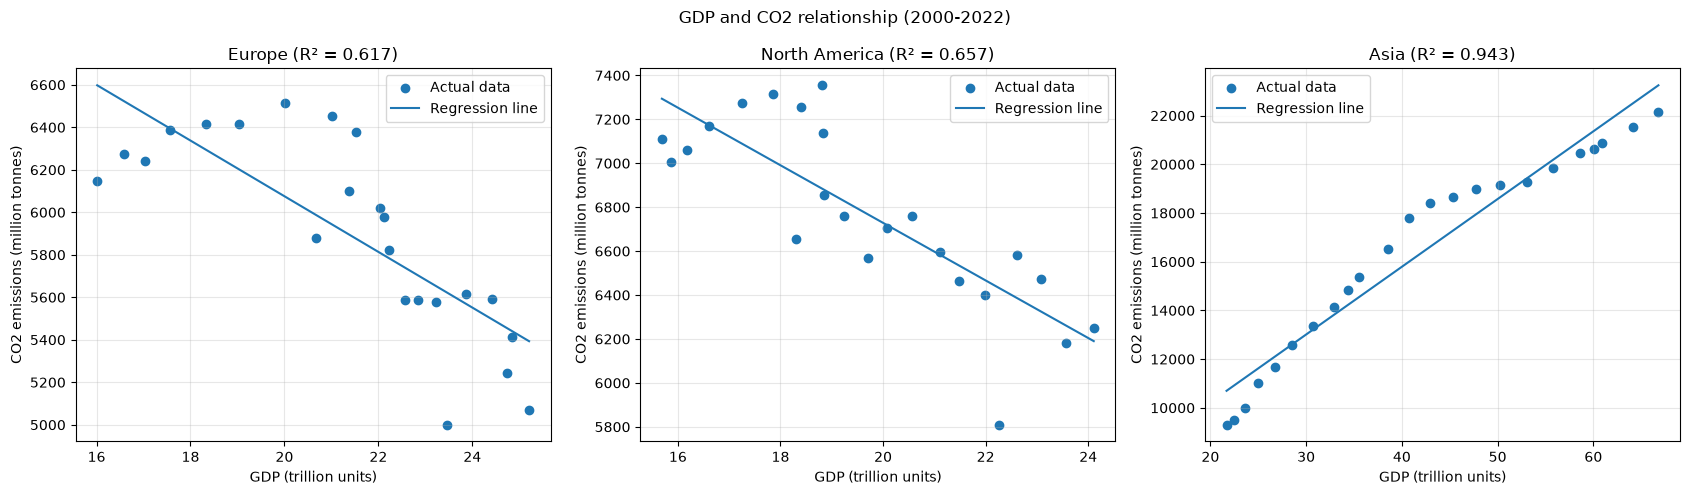

In [34]:
# make the same work for the 2000-2022 period
recent_data = df_continents[
    (df_continents['continent'].isin(
        ['Europe', 'North America', 'Asia']
    )) &
    (df_continents['year'].between(2000, 2022))
].copy()

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, continent in zip(
    axes, ['Europe', 'North America', 'Asia']
):

    data = recent_data[
        recent_data['continent'] == continent
    ]

    x = data['gdp'] / 1e12
    y = data['co2']

    slope, intercept = np.polyfit(x, y, 1)

    y_pred = slope * x + intercept

    r2 = np.corrcoef(x, y)[0, 1] ** 2

    x_line = np.linspace(x.min(), x.max(), 100)

    ax.scatter(x, y, label='Actual data')
    ax.plot(
        x_line,
        slope * x_line + intercept,
        label='Regression line'
    )

    ax.set_title(f'{continent} (R² = {r2:.3f})')
    ax.set_xlabel('GDP (trillion units)')
    ax.set_ylabel('CO2 emissions (million tonnes)')
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle('GDP and CO2 relationship (2000-2022)')
plt.tight_layout()
plt.show()

As suggested by the previous plot, in more recent years there has been a reversal in the relationship between GDP and CO₂ emissions in Europe and North America. This is confirmed by the negative slopes of the regression lines. 

For Asia, instead, the positive relationship between GDP and emissions is confirmed.

These results may partly be explained by the strict environmental regulations implemented in Europe and North America, as well as by significant investments in sustainability and cleaner technologies, in addition to the transition to renewable sources.

In Asia, on the other hand, rapidly growing economies such as China and India may still show a positive relationship between GDP and emissions because economic growth has been largely driven by industrial production and other energy-intensive activities.

Furthermore, many companies have relocated their production activities to Asian countries, potentially shifting part of their carbon emissions from Western countries to Asia. This phenomenon is called carbon leakage.

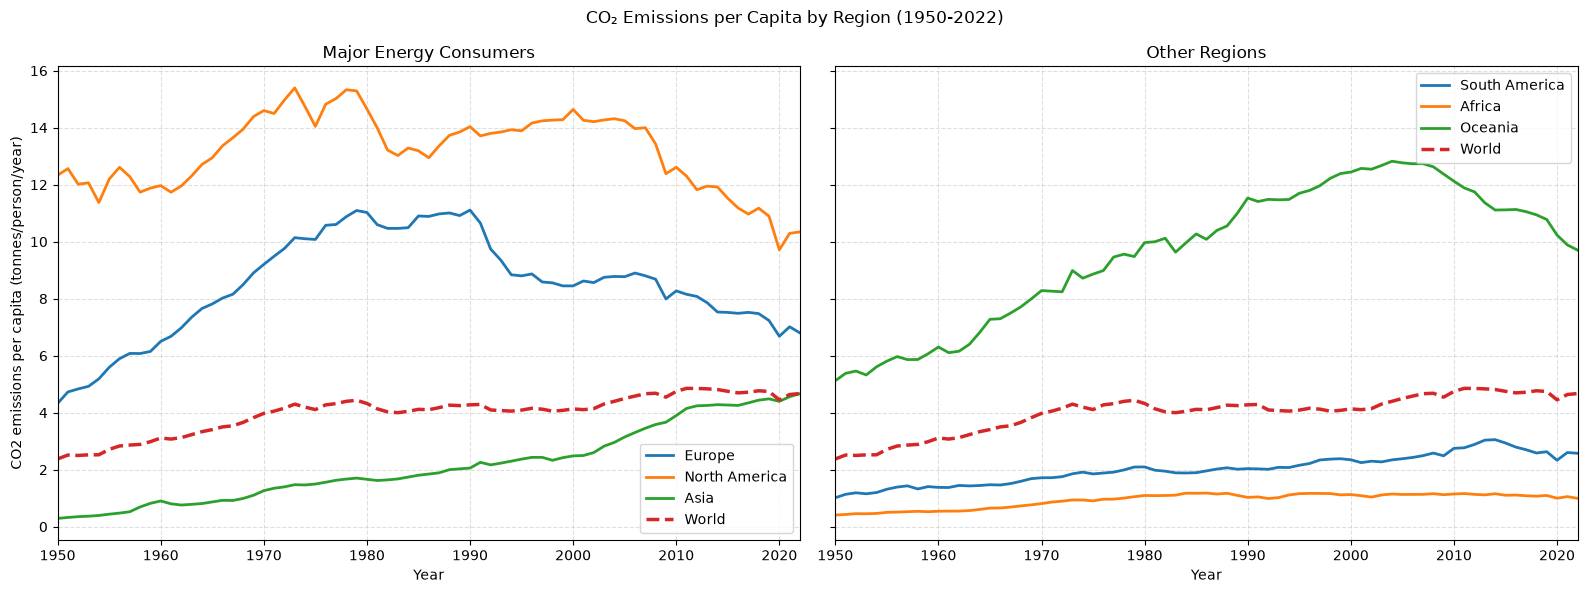

In [35]:
# studying per capita emissions
df_co2_regions['co2_per_capita'] = (
    df_co2_regions['co2'] * 1_000_000 /
    df_co2_regions['population']
)


target_regions_1 = ['Europe', 'North America', 'Asia', 'World']
target_regions_2 = ['South America', 'Africa', 'Oceania', 'World']

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

for ax, target_regions in zip(axes, [target_regions_1, target_regions_2]):

    for region in target_regions:
        df_temp = df_co2_regions[
            df_co2_regions['country'] == region
        ].sort_values('year')

        ax.plot(
            df_temp['year'],
            df_temp['co2_per_capita'],
            label=region,
            linewidth=2.5 if region == 'World' else 2,
            linestyle='--' if region == 'World' else '-'
        )

    ax.set_xlabel('Year')
    ax.set_xlim(1950, 2022)
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend()

axes[0].set_title('Major Energy Consumers')
axes[1].set_title('Other Regions')
axes[0].set_ylabel('CO2 emissions per capita (tonnes/person/year)')

fig.suptitle('CO₂ Emissions per Capita by Region (1950-2022)')
plt.tight_layout()
plt.show()

Analyzing emissions on a per capita basis provides a more nuanced and accurate perspective on the actual environmental footprint of these regions. Comparing aggregate emissions directly can be misleading, as it does not account for substantial demographic disparities across geographic areas. While absolute figures remain essential for assessing total atmospheric impact and identifying macro-trends, evaluating emissions relative to population size is crucial for contextualizing regional efficiency and lifestyle-driven consumption.

This adjustment reveals a critical insight that was not immediately evident from the aggregate emission plots: North America exhibits significantly higher per capita CO₂ emissions than both Europe and Major Asia. This suggests that, despite the progress made in reducing total emissions in recent decades, its average carbon footprint remains considerably higher. This may be partly explained by higher levels of energy consumption, car dependency, larger living spaces and consumption-intensive lifestyles. Therefore, although North America has achieved some degree of decoupling between economic growth and total emissions, its per capita environmental impact remains particularly high.